<a href="https://colab.research.google.com/github/josuelferreirafilho/Data-Science/blob/main/01_regressao_linear_do_zero.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Regressão Linear do zero

**Objetivo:** entender o que acontece "por baixo do capô" de um `LinearRegression().fit()`.

1. Explorar um dataset real: preços de imóveis da Califórnia (Censo dos EUA, 1990)
2. Correlação e regressão linear simples — e a relação $\hat\beta_1 = r\, s_y/s_x$
3. OLS pela fórmula fechada $(X^\top X)^{-1}X^\top y$ em NumPy
4. OLS por **gradiente descendente** (o mesmo mecanismo que treina redes neurais)
5. Comparar com `scikit-learn` e `statsmodels`
6. Regressão múltipla e interpretação dos coeficientes

📖 Teoria: [teoria/02_regressao_linear.md](../teoria/02_regressao_linear.md)

> **Rodando no Google Colab?** Execute a célula abaixo primeiro: ela baixa os dados (fontes públicas originais). Fora do Colab ela não faz nada.

In [ ]:
# ⚙️ Setup para Google Colab — fora do Colab esta célula não faz nada
import sys, os, pathlib, urllib.request, subprocess
if "google.colab" in sys.modules:
    base = pathlib.Path("/content/aula02")
    (base / "data").mkdir(parents=True, exist_ok=True)
    (base / "notebooks").mkdir(exist_ok=True)
    urls = {
        "housing.csv": "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv",
    }
    for fname, url in urls.items():
        if not (base / "data" / fname).exists():
            urllib.request.urlretrieve(url, base / "data" / fname)
    os.chdir(base / "notebooks")
    sys.path.insert(0, str(base / "notebooks"))
    print("Ambiente Colab pronto:", os.listdir(base / "data"))

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
RNG = np.random.default_rng(42)

## 1. Os dados

Cada linha é um **quarteirão censitário** (*block group*) da Califórnia. O alvo é `median_house_value` (valor mediano das casas, em US$).

| Coluna | Descrição |
|---|---|
| `median_income` | Renda mediana do quarteirão (em dezenas de milhares de US$) |
| `housing_median_age` | Idade mediana dos imóveis |
| `total_rooms`, `total_bedrooms` | Total de cômodos / quartos no quarteirão |
| `population`, `households` | População e nº de domicílios |
| `latitude`, `longitude` | Localização |
| `ocean_proximity` | Distância do oceano (categórica) |

In [ ]:
df = pd.read_csv("../data/housing.csv")
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.2300,37.8800,41.0000,880.0000,129.0000,322.0000,126.0000,8.3252,"452,600.0000",NEAR BAY
1,-122.2200,37.8600,21.0000,"7,099.0000","1,106.0000","2,401.0000","1,138.0000",8.3014,"358,500.0000",NEAR BAY
2,-122.2400,37.8500,52.0000,"1,467.0000",190.0000,496.0000,177.0000,7.2574,"352,100.0000",NEAR BAY
3,-122.2500,37.8500,52.0000,"1,274.0000",235.0000,558.0000,219.0000,5.6431,"341,300.0000",NEAR BAY
4,-122.2500,37.8500,52.0000,"1,627.0000",280.0000,565.0000,259.0000,3.8462,"342,200.0000",NEAR BAY


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,"20,640.0000",-119.5697,2.0035,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
latitude,"20,640.0000",35.6319,2.1360,32.5400,33.9300,34.2600,37.7100,41.9500
housing_median_age,"20,640.0000",28.6395,12.5856,1.0000,18.0000,29.0000,37.0000,52.0000
total_rooms,"20,640.0000","2,635.7631","2,181.6153",2.0000,"1,447.7500","2,127.0000","3,148.0000","39,320.0000"
total_bedrooms,"20,433.0000",537.8706,421.3851,1.0000,296.0000,435.0000,647.0000,"6,445.0000"
population,"20,640.0000","1,425.4767","1,132.4621",3.0000,787.0000,"1,166.0000","1,725.0000","35,682.0000"
households,"20,640.0000",499.5397,382.3298,1.0000,280.0000,409.0000,605.0000,"6,082.0000"
median_income,"20,640.0000",3.8707,1.8998,0.4999,2.5634,3.5348,4.7432,15.0001
median_house_value,"20,640.0000","206,855.8169","115,395.6159","14,999.0000","119,600.0000","179,700.0000","264,725.0000","500,001.0000"


⚠️ Observe o máximo de `median_house_value` = **500.001**: os valores foram **truncados (censurados)** no censo. Muitos quarteirões caros aparecem com esse teto. Para fins didáticos vamos removê-los neste notebook, mas guarde isso: *a forma como os dados foram coletados afeta o que o modelo aprende*.

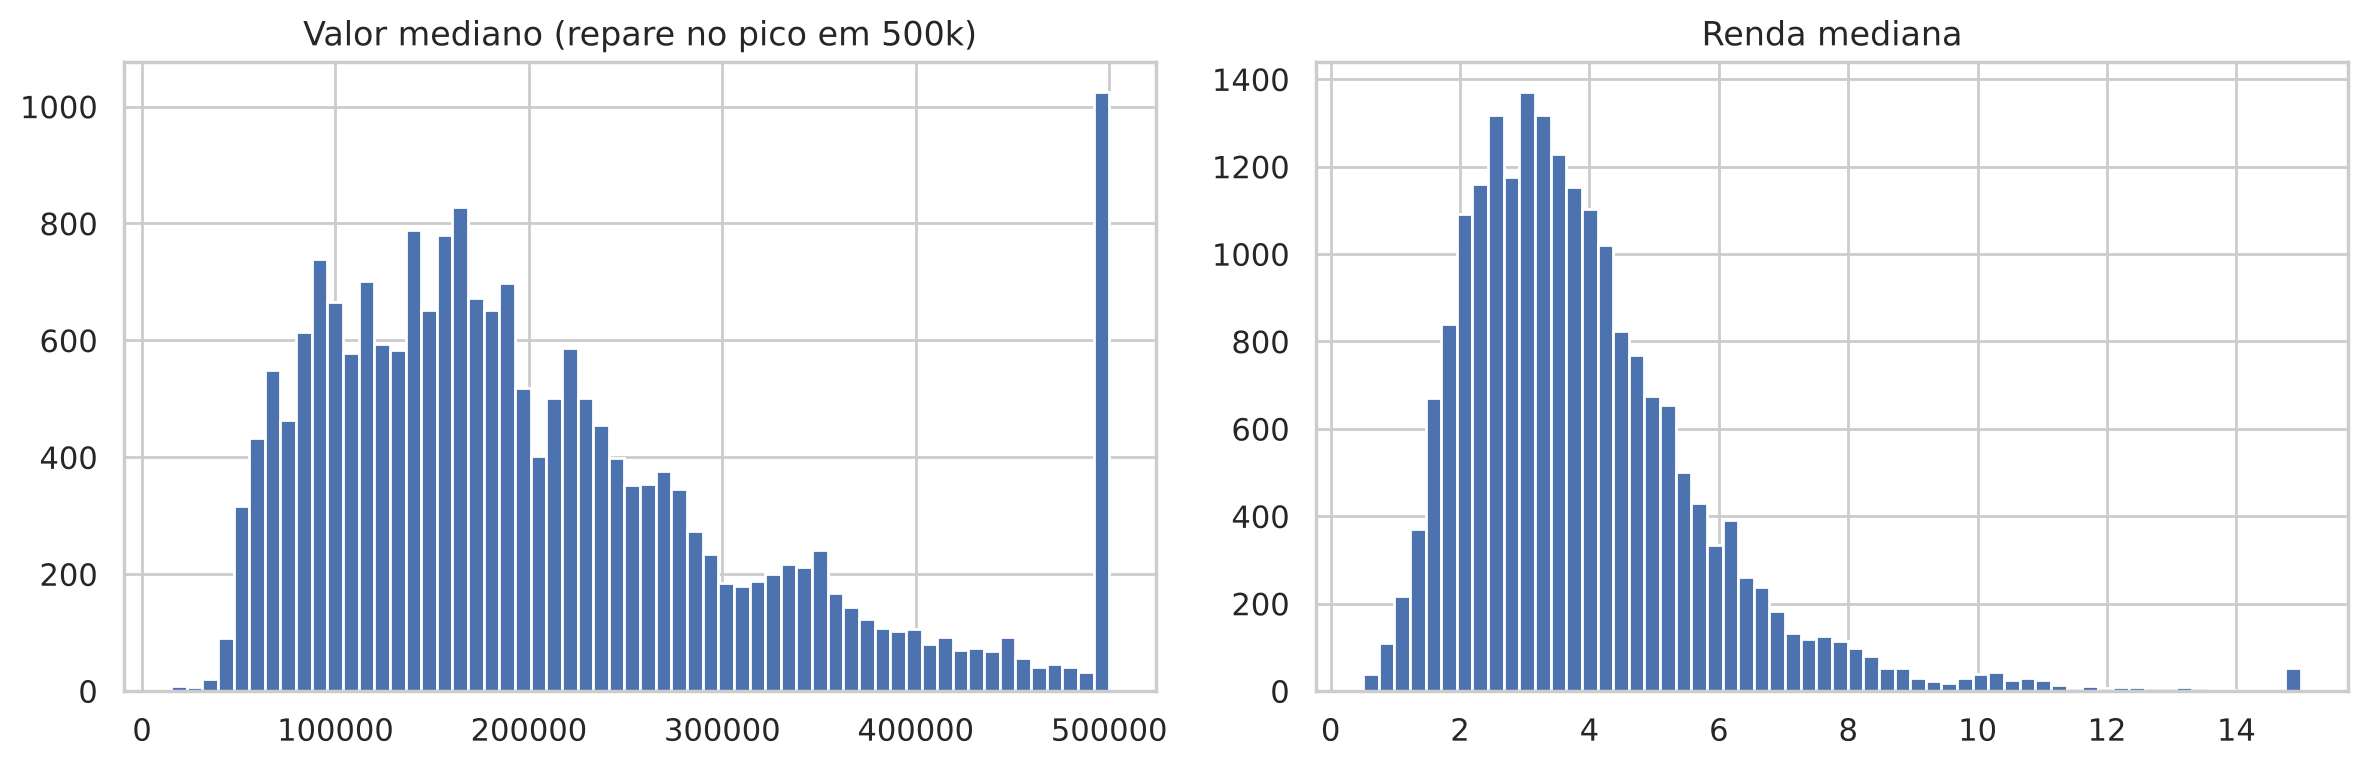

(19448, 13)


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["median_house_value"].hist(bins=60, ax=ax[0]); ax[0].set_title("Valor mediano (repare no pico em 500k)")
df["median_income"].hist(bins=60, ax=ax[1]); ax[1].set_title("Renda mediana")
plt.tight_layout(); plt.show()

df = df[df["median_house_value"] < 500_000].copy()
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df = df.dropna()
print(df.shape)

## 2. Correlação

Antes de qualquer modelo: quais variáveis andam junto com o preço?

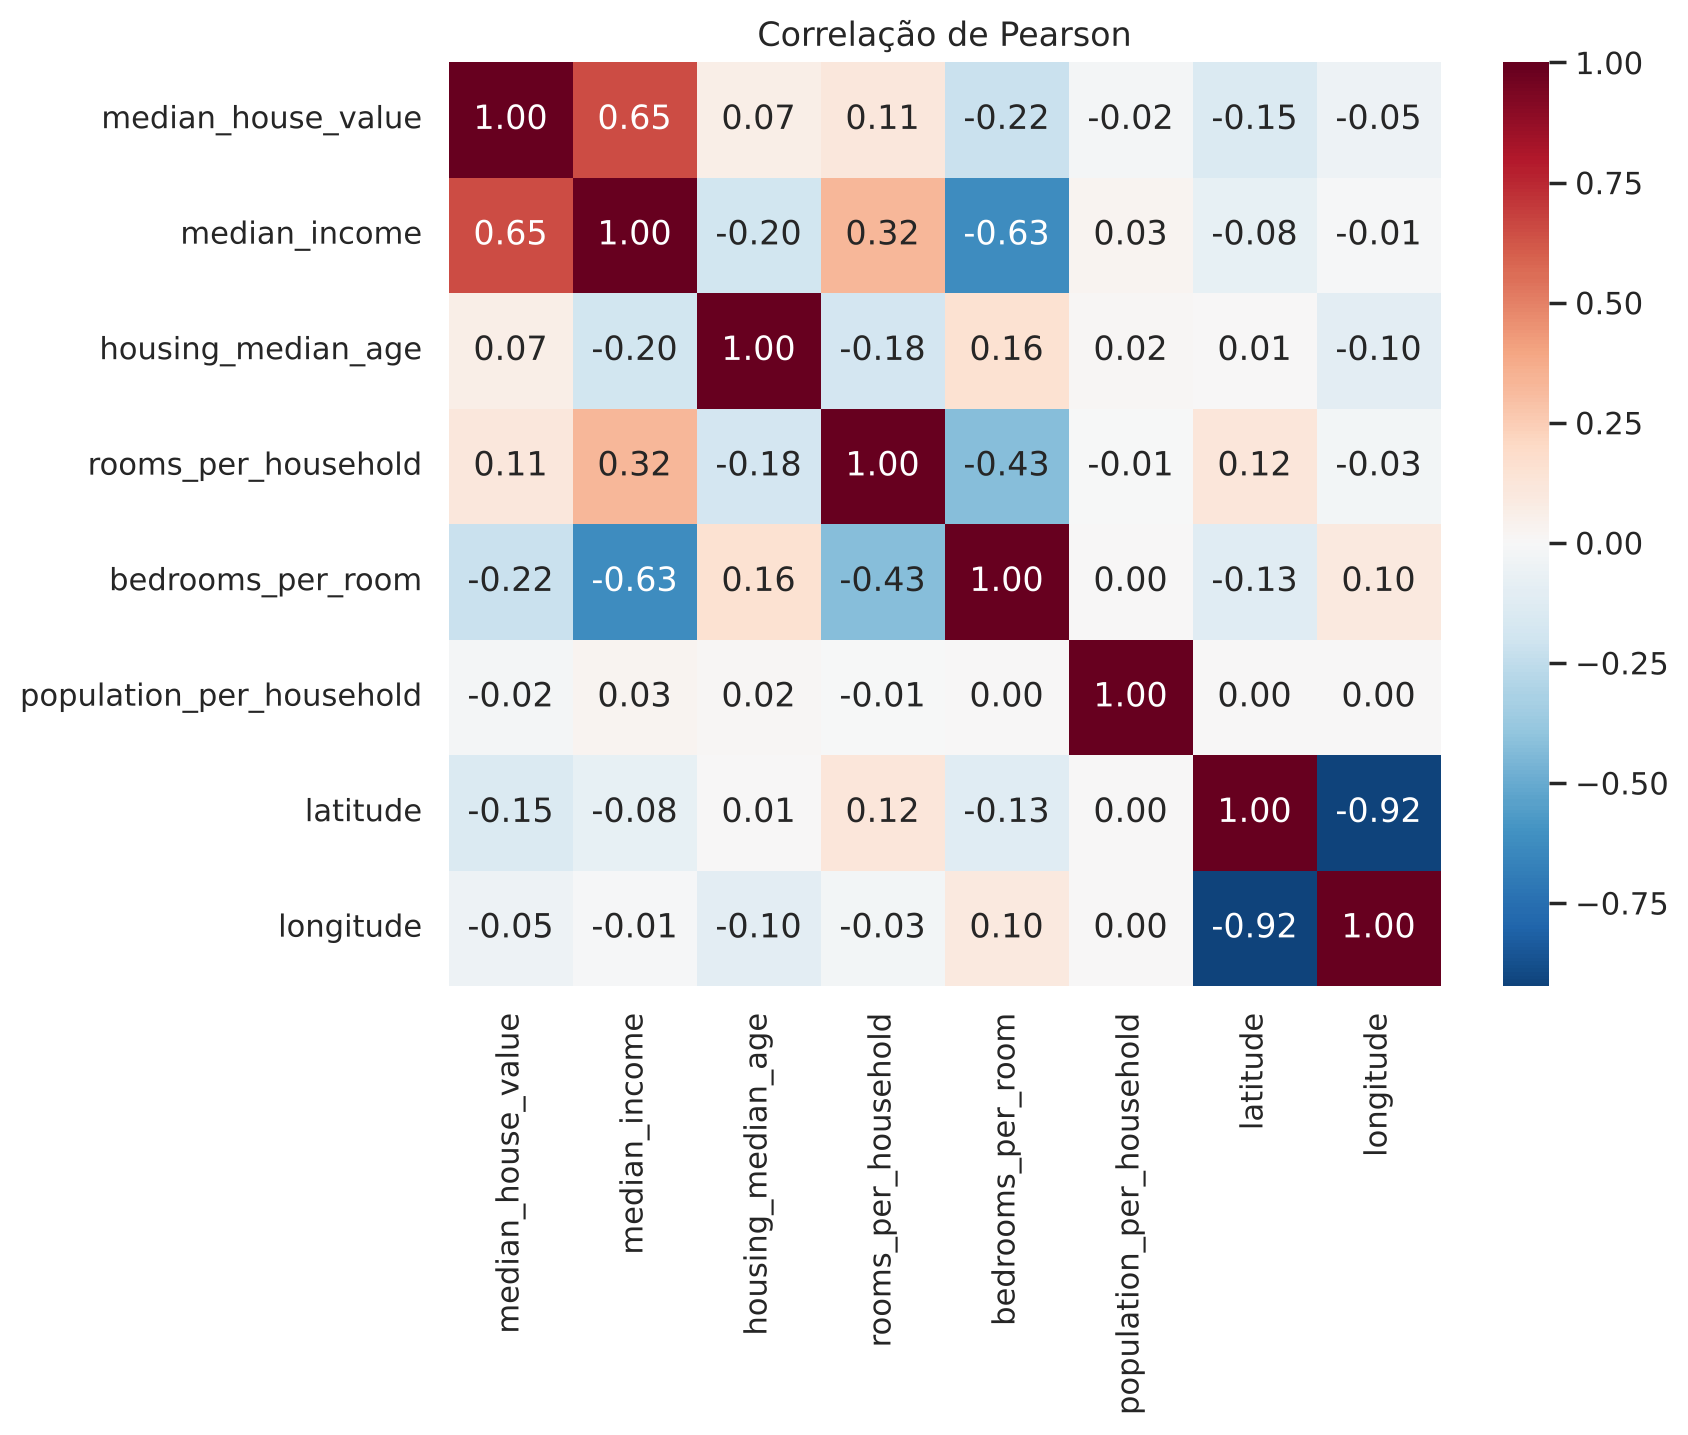

In [ ]:
num_cols = ["median_house_value", "median_income", "housing_median_age", "rooms_per_household",
            "bedrooms_per_room", "population_per_household", "latitude", "longitude"]
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlação de Pearson"); plt.show()

In [ ]:
pd.DataFrame({
    "pearson": df[num_cols].corr(method="pearson")["median_house_value"],
    "spearman": df[num_cols].corr(method="spearman")["median_house_value"],
}).drop("median_house_value").sort_values("pearson", ascending=False)

,pearson,spearman
median_income,0.6469,0.6523
rooms_per_household,0.1109,0.2188
housing_median_age,0.0658,0.0461
population_per_household,-0.0211,-0.2295
longitude,-0.0453,-0.0593
latitude,-0.1496,-0.1687
bedrooms_per_room,-0.2200,-0.2969


`median_income` é de longe a variável mais associada ao preço. Mas lembre: **associação** — renda alta não "causa" casa cara diretamente; ambos refletem localização, escolas, empregos... (capítulo 5).

## 3. Regressão linear simples: preço ~ renda

$$\text{preço}_i = \beta_0 + \beta_1\,\text{renda}_i + \varepsilon_i$$

### 3.1 Pelas fórmulas da regressão simples

In [ ]:
x = df["median_income"].to_numpy()
y = df["median_house_value"].to_numpy()

beta1 = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
beta0 = y.mean() - beta1 * x.mean()

r = np.corrcoef(x, y)[0, 1]
beta1_via_r = r * y.std(ddof=1) / x.std(ddof=1)

print(f"β0 = {beta0:,.2f}")
print(f"β1 = {beta1:,.2f}   (via correlação: {beta1_via_r:,.2f})")
print(f"r = {r:.4f}  →  r² = {r**2:.4f}")

β0 = 44,899.45
β1 = 40,016.60   (via correlação: 40,016.60)
r = 0.6469  →  r² = 0.4185


**Leitura:** cada +1 unidade de `median_income` (= +US$ 10 mil de renda) está associada a ≈ +US$ 40 mil no valor mediano do imóvel. O intercepto (≈ US$ 45 mil) seria o preço com renda zero — uma extrapolação sem sentido prático, pois não há quarteirões com renda zero nos dados.

E veja: **a inclinação é só a correlação reescalada**.

### 3.2 Pela forma matricial (equações normais)

$$\hat{\boldsymbol\beta} = (X^\top X)^{-1}X^\top y$$

In [ ]:
X = np.column_stack([np.ones_like(x), x])          # coluna de 1s = intercepto
beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y
# Na prática, use solve/lstsq (numericamente mais estável que inverter):
beta_lstsq, *_ = np.linalg.lstsq(X, y, rcond=None)
print("inv :", beta_hat)
print("lstsq:", beta_lstsq)

inv : [44899.44863882 40016.59681061]
lstsq: [44899.44863882 40016.59681061]


### 3.3 Por gradiente descendente

$$\beta \leftarrow \beta - \eta\,\nabla \text{MSE},\qquad \nabla\text{MSE} = -\tfrac{2}{n}X^\top(y - X\beta)$$

Padronizamos $x$ e $y$ para o gradiente convergir bem (mesma recomendação das redes neurais), e depois voltamos para a escala original.

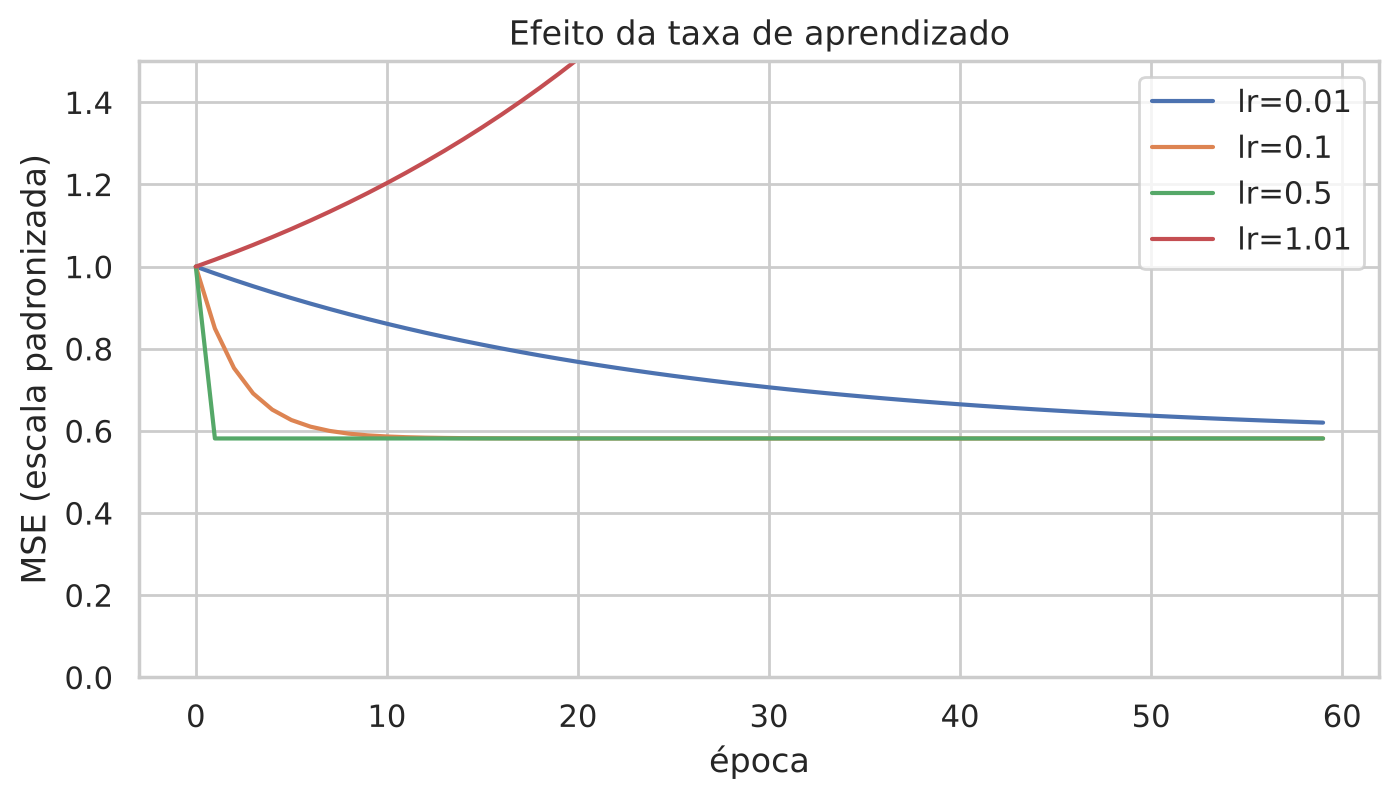

Gradiente descendente: β0 = 44,899.45, β1 = 40,016.60


In [ ]:
def gradient_descent(X, y, lr=0.1, epochs=200):
    n, p = X.shape
    beta = np.zeros(p)
    history = []
    for _ in range(epochs):
        y_hat = X @ beta
        grad = -2 / n * X.T @ (y - y_hat)
        beta -= lr * grad
        history.append(np.mean((y - y_hat) ** 2))
    return beta, history

xs = (x - x.mean()) / x.std(); ys = (y - y.mean()) / y.std()
Xs = np.column_stack([np.ones_like(xs), xs])

fig, ax = plt.subplots(figsize=(8, 4))
for lr in [0.01, 0.1, 0.5, 1.01]:
    b, hist = gradient_descent(Xs, ys, lr=lr, epochs=60)
    ax.plot(hist, label=f"lr={lr}")
ax.set_ylim(0, 1.5); ax.set_xlabel("época"); ax.set_ylabel("MSE (escala padronizada)")
ax.set_title("Efeito da taxa de aprendizado"); ax.legend(); plt.show()

b_std, _ = gradient_descent(Xs, ys, lr=0.1, epochs=500)
beta1_gd = b_std[1] * y.std() / x.std()
beta0_gd = y.mean() + y.std() * b_std[0] - beta1_gd * x.mean()
print(f"Gradiente descendente: β0 = {beta0_gd:,.2f}, β1 = {beta1_gd:,.2f}")

- `lr` pequeno: converge devagar.
- `lr` grande demais (1.01): **diverge**.
- No ponto ótimo, chegamos ao mesmo resultado da fórmula fechada. Note também que, na escala padronizada, $\beta_1 = r$.

### 3.4 Conferindo com scikit-learn e statsmodels

In [ ]:
lr_sk = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"scikit-learn: β0 = {lr_sk.intercept_:,.2f}, β1 = {lr_sk.coef_[0]:,.2f}, R² = {lr_sk.score(x.reshape(-1,1), y):.4f}")

ols = sm.OLS(y, sm.add_constant(x)).fit()
print(ols.summary(xname=["const", "median_income"]))

scikit-learn: β0 = 44,899.45, β1 = 40,016.60, R² = 0.4185


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.418
Model:                            OLS   Adj. R-squared:                  0.418
Method:                 Least Squares   F-statistic:                 1.399e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:12:23   Log-Likelihood:            -2.4565e+05
No. Observations:               19448   AIC:                         4.913e+05
Df Residuals:                   19446   BIC:                         4.913e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           4.49e+04   1352.286     33.203

O `statsmodels` adiciona a parte **inferencial**: erro-padrão, estatística t, p-valor, intervalo de confiança, F, AIC/BIC e alguns diagnósticos (Durbin-Watson, Jarque-Bera). O `scikit-learn` é focado em **previsão**.

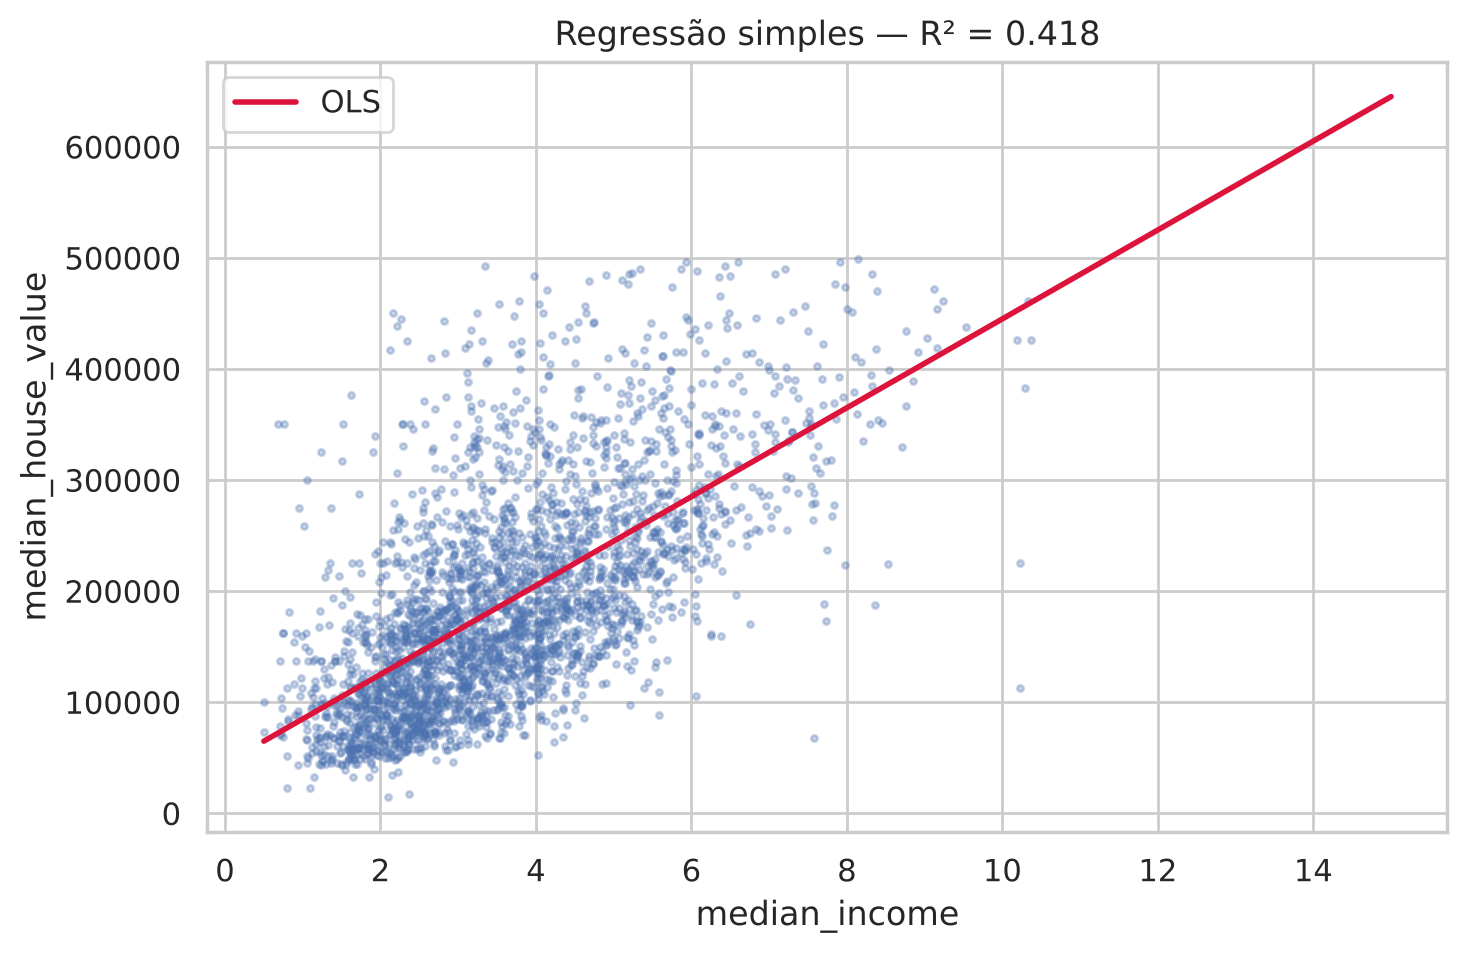

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
idx = RNG.choice(len(x), 3000, replace=False)
ax.scatter(x[idx], y[idx], s=5, alpha=0.3)
grid = np.linspace(x.min(), x.max(), 100)
ax.plot(grid, beta0 + beta1 * grid, color="crimson", lw=2, label="OLS")
ax.set_xlabel("median_income"); ax.set_ylabel("median_house_value"); ax.legend()
ax.set_title(f"Regressão simples — R² = {r**2:.3f}"); plt.show()

## 4. Regressão múltipla

Agora com várias variáveis. Cada $\beta_j$ passa a ser a associação de $x_j$ com $y$ **mantendo as outras variáveis do modelo constantes**.

In [ ]:
features = ["median_income", "housing_median_age", "rooms_per_household",
            "bedrooms_per_room", "population_per_household", "latitude", "longitude"]
Xm = sm.add_constant(df[features])
ols_m = sm.OLS(df["median_house_value"], Xm).fit()
print(ols_m.summary())

                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.585
Model:                            OLS   Adj. R-squared:                  0.584
Method:                 Least Squares   F-statistic:                     3909.
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:12:23   Log-Likelihood:            -2.4238e+05
No. Observations:               19448   AIC:                         4.848e+05
Df Residuals:                   19440   BIC:                         4.848e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

In [ ]:
comp = pd.DataFrame({
    "β simples (só renda)": [ols.params[1]],
    "β múltipla (com controles)": [ols_m.params["median_income"]],
}, index=["median_income"])
comp

,β simples (só renda),β múltipla (com controles)
median_income,"40,016.5968","43,753.1724"


O coeficiente da renda **mudou** (de ≈ 40 mil para ≈ 44 mil) quando incluímos outras variáveis. Isso é o **viés de variável omitida** em ação: a regressão simples misturava o efeito da renda com o de variáveis correlacionadas com ela (localização, densidade, tamanho dos imóveis). Aqui o viés era **para baixo** — omitir variáveis não necessariamente infla o coeficiente; o sinal do viés depende da fórmula do OVB (teoria, cap. 5.4).

Pergunta para a turma: **qual dos dois é o "efeito da renda"?** Resposta: nenhum, necessariamente. Depende de quais variáveis são confundidoras e quais são mediadoras — e isso não está nos dados. Veja o [notebook 05](05_correlacao_vs_causalidade.ipynb).

### Coeficientes padronizados
Coeficientes brutos dependem da unidade de cada variável. Para comparar "importâncias" dentro do modelo, padronizamos as features.

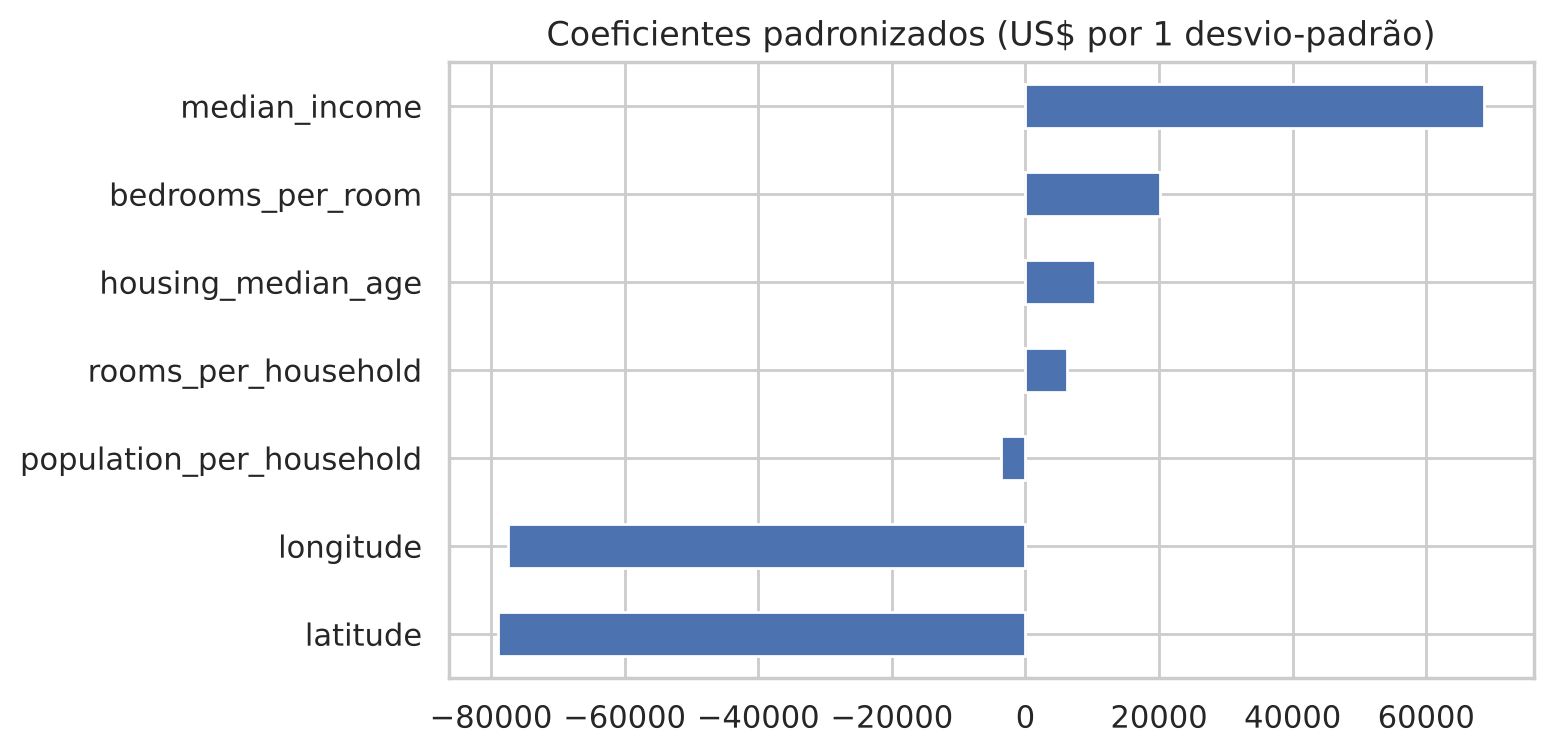

In [ ]:
Z = (df[features] - df[features].mean()) / df[features].std()
ols_std = sm.OLS(df["median_house_value"], sm.add_constant(Z)).fit()
ax = ols_std.params.drop("const").sort_values().plot.barh(figsize=(7, 4))
ax.set_title("Coeficientes padronizados (US$ por 1 desvio-padrão)"); plt.show()

## Resumo

- Regressão linear = encontrar a reta/hiperplano que minimiza a soma dos quadrados dos resíduos.
- Fórmula fechada, `lstsq`, gradiente descendente, scikit-learn e statsmodels chegam ao **mesmo** resultado.
- Gradiente descendente é a ponte para **redes neurais** (notebook 03).
- O coeficiente da regressão simples é a correlação reescalada; na múltipla, ele muda conforme os controles → interpretação causal exige cuidado.

### 🛠️ Hands on
1. Ajuste `log(median_house_value) ~ log(median_income)`. Como interpretar o coeficiente agora?
2. Inclua `ocean_proximity` como dummies (`pd.get_dummies`). O que acontece com o coeficiente de `latitude`?
3. Implemente o gradiente descendente para a regressão **múltipla** (dica: o código já funciona para qualquer `X`).